In [1]:
import ee
ee.Initialize(project="tree-fire-510209")

florida_bbox = ee.Geometry.Rectangle([-85.6, 30.0, -84.9, 30.6])

agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")

for year in [2017, 2019]:
    img = agb.filterDate(f"{year}-01-01", f"{year}-12-31").first()
    url = img.getDownloadURL({"scale": 100, "region": florida_bbox, "format": "GEO_TIFF"})
    print(year, url)


2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/02cfefb5a997c7c15e06f278fd92f750-7ac333d698ac0009d471e2d068b352a6:getPixels
2019 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/b288150c79cd796b921518f7c1f5192e-3ae8cc9ecd172d6ac20acda9de9e7bb3:getPixels


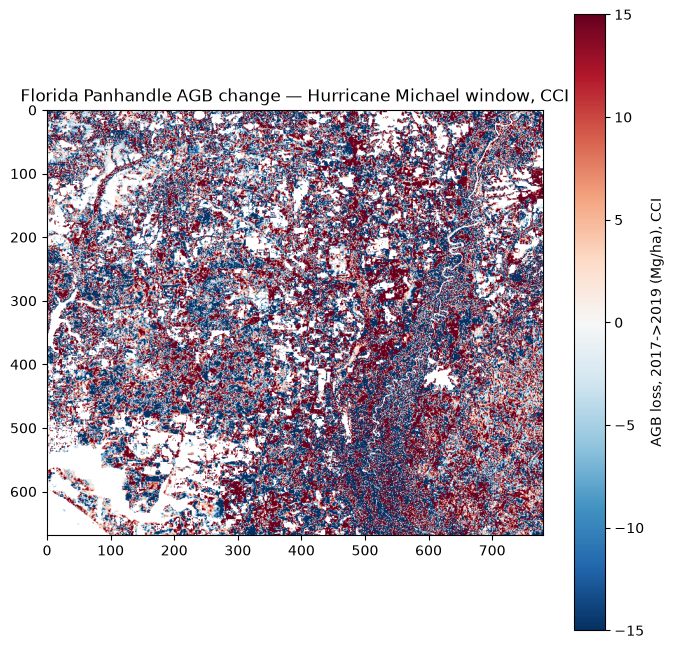

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("../data/raw/agb/agb_florida_2017.tif") as src:
    agb_2017 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_florida_2019.tif") as src:
    agb_2019 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss_florida = agb_2017 - agb_2019

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_florida, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(im, label="AGB loss, 2017->2019 (Mg/ha), CCI")
plt.title("Florida Panhandle AGB change — Hurricane Michael window, CCI")
plt.savefig("../data/raw/cci_loss_florida.png", dpi=150)
plt.show()


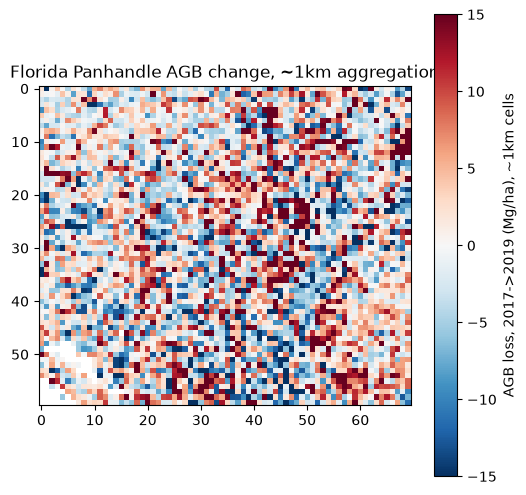

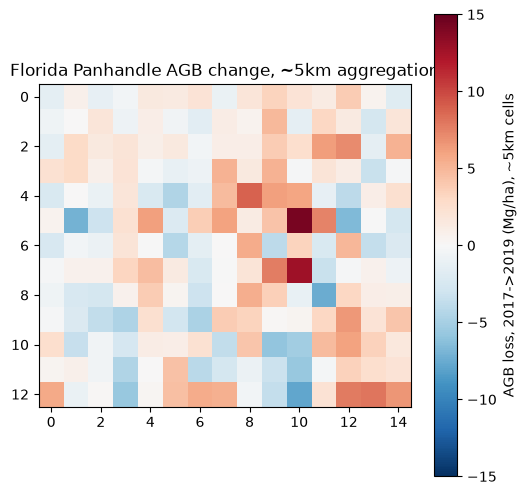

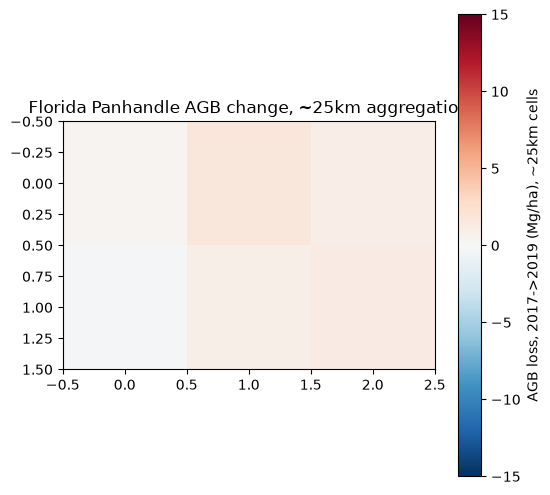

In [3]:
import sys
sys.path.insert(0, "../src")
from grids import reproject_to_grid
from rasterio.transform import from_origin
from rasterio.warp import Resampling

def aggregate(path, cell_size_deg):
    with rasterio.open(path) as src:
        arr = src.read(1)
        src_transform, src_crs = src.transform, src.crs
        bounds = src.bounds
        nodata = src.nodata

    width = int((bounds.right - bounds.left) / cell_size_deg)
    height = int((bounds.top - bounds.bottom) / cell_size_deg)
    dst_transform = from_origin(bounds.left, bounds.top, cell_size_deg, cell_size_deg)

    return reproject_to_grid(
        arr, src_transform, src_crs,
        dst_shape=(height, width), dst_transform=dst_transform, dst_crs=src_crs,
        resampling=Resampling.average, src_nodata=nodata,
    )

cell_sizes_deg = {"~1km": 0.01, "~5km": 0.045, "~25km": 0.225}

for label, cell_size in cell_sizes_deg.items():
    agb_2017_agg = aggregate("../data/raw/agb/agb_florida_2017.tif", cell_size)
    agb_2019_agg = aggregate("../data/raw/agb/agb_florida_2019.tif", cell_size)
    loss_agg = agb_2017_agg - agb_2019_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2017->2019 (Mg/ha), {label} cells")
    plt.title(f"Florida Panhandle AGB change, {label} aggregation")
    plt.savefig(f"../data/raw/cci_loss_florida_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()


In [4]:
florida_bbox_v2 = ee.Geometry.Rectangle([-85.7, 29.6, -84.6, 30.6])

for year in [2017, 2019]:
    img = agb.filterDate(f"{year}-01-01", f"{year}-12-31").first()
    url = img.getDownloadURL({"scale": 100, "region": florida_bbox_v2, "format": "GEO_TIFF"})
    print(year, url)


2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/e21ab4af0590945cc9c916adcc0a6af5-ed118b59883e96e9b1f79338bd721abc:getPixels
2019 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/d3c7c04b16e9e15ffc5500887be2507a-4a65227e8c837f4735917ee04e64db4a:getPixels


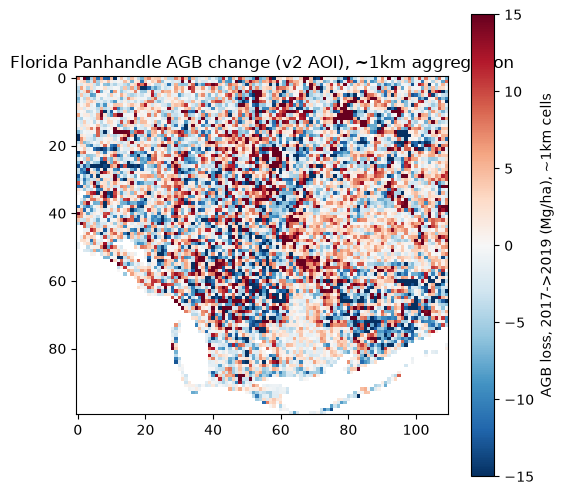

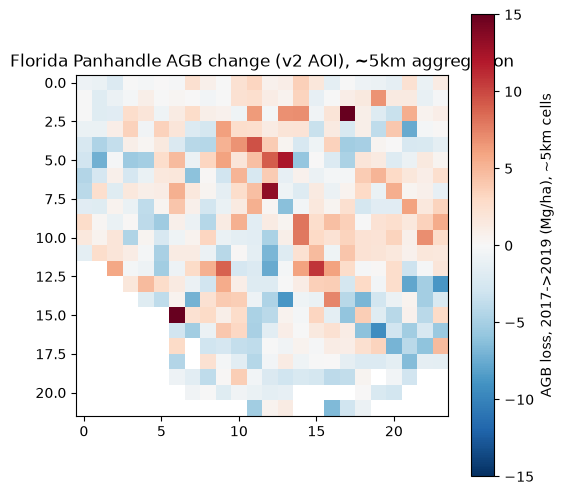

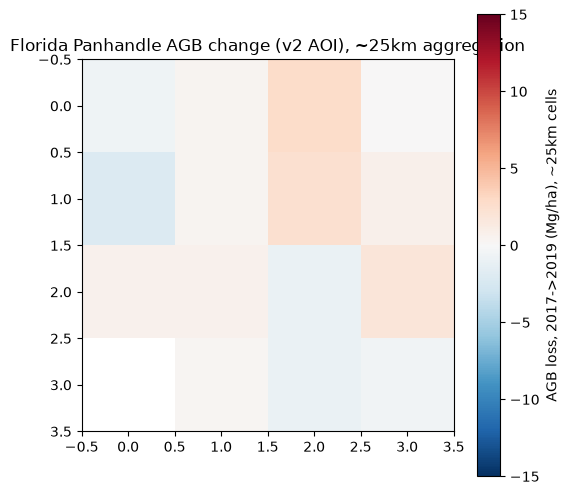

In [5]:
cell_sizes_deg = {"~1km": 0.01, "~5km": 0.045, "~25km": 0.225}

for label, cell_size in cell_sizes_deg.items():
    agb_2017_agg = aggregate("../data/raw/agb/agb_florida_v2_2017.tif", cell_size)
    agb_2019_agg = aggregate("../data/raw/agb/agb_florida_v2_2019.tif", cell_size)
    loss_agg = agb_2017_agg - agb_2019_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2017->2019 (Mg/ha), {label} cells")
    plt.title(f"Florida Panhandle AGB change (v2 AOI), {label} aggregation")
    plt.savefig(f"../data/raw/cci_loss_florida_v2_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()


In [6]:
hansen = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")
lossyear = hansen.select("lossyear")

url_lossyear = lossyear.getDownloadURL({"scale": 100, "region": florida_bbox_v2, "format": "GEO_TIFF"})
print(url_lossyear)


/home/jupyter/climate_impact_curves/.venv/lib/python3.12/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2023_v1_11! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2023_v1_11

  warnings.warn(warning, category=DeprecationWarning)


https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/381cb662e99af2fbd52cf26322041c13-16923ddb1e71c1447d6d9d2a4dffb86b:getPixels


fraction of bbox with Hansen-detected 2018 canopy loss: 0.040838270792187846


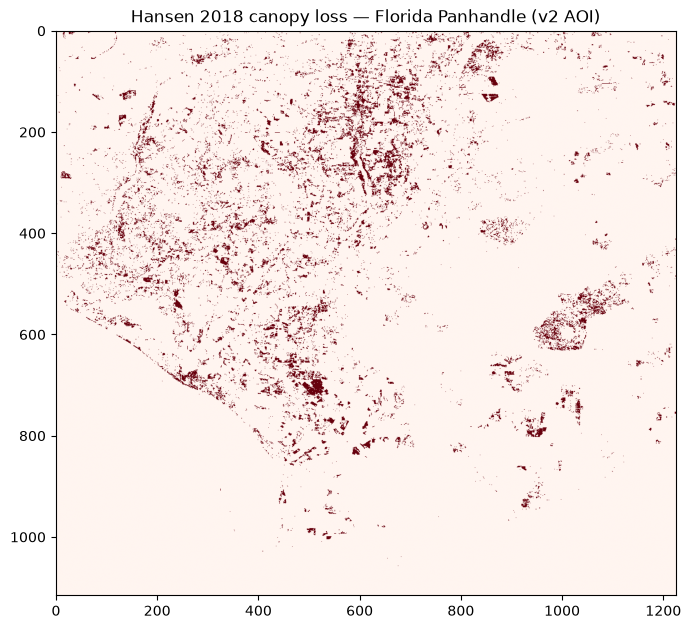

In [7]:
with rasterio.open("../data/raw/hansen_lossyear_florida_v2.tif") as src:
    lossyear = src.read(1)

loss_2018 = lossyear == 18
print("fraction of bbox with Hansen-detected 2018 canopy loss:", loss_2018.mean())

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(loss_2018, cmap="Reds")
plt.title("Hansen 2018 canopy loss — Florida Panhandle (v2 AOI)")
plt.savefig("../data/raw/hansen_2018_loss_florida.png", dpi=150)
plt.show()


In [8]:
for year, code in [(2016, 16), (2017, 17), (2019, 19)]:
    loss_year = lossyear == code
    print(f"fraction of bbox with Hansen-detected {year} canopy loss:", loss_year.mean())


fraction of bbox with Hansen-detected 2016 canopy loss: 0.02122302684514666
fraction of bbox with Hansen-detected 2017 canopy loss: 0.018478531197425208
fraction of bbox with Hansen-detected 2019 canopy loss: 0.05025235900811938


In [9]:
georgia_control_bbox = ee.Geometry.Rectangle([-83.5, 31.0, -82.8, 31.6])

hansen_gc = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")
lossyear_gc = hansen_gc.select("lossyear")

url_control = lossyear_gc.getDownloadURL({"scale": 100, "region": georgia_control_bbox, "format": "GEO_TIFF"})
print(url_control)


https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/315ce64d2fe248860a294d1ff58ffd40-ef9c4b43878bd0fbf2f617719cd5c2b5:getPixels


In [10]:
with rasterio.open("../data/raw/hansen_lossyear_georgia_control.tif") as src:
    lossyear_gc_arr = src.read(1)

for year, code in [(2016, 16), (2017, 17), (2018, 18), (2019, 19)]:
    loss_year = lossyear_gc_arr == code
    print(f"control region, {year} canopy loss fraction:", loss_year.mean())


control region, 2016 canopy loss fraction: 0.019092790617454294
control region, 2017 canopy loss fraction: 0.02087501437277222
control region, 2018 canopy loss fraction: 0.015834962247518302
control region, 2019 canopy loss fraction: 0.015627994327545896


In [11]:
for year in [2017, 2020]:
    img = agb.filterDate(f"{year}-01-01", f"{year}-12-31").first()
    url = img.getDownloadURL({"scale": 100, "region": florida_bbox_v2, "format": "GEO_TIFF"})
    print(year, url)


2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/e21ab4af0590945cc9c916adcc0a6af5-cdd32c4e00050dbaa79b012091b512cf:getPixels
2020 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/ab03be5607a441a4d304ce7f8e90128e-0ba8918980be779fad68ec4883c8cb0d:getPixels


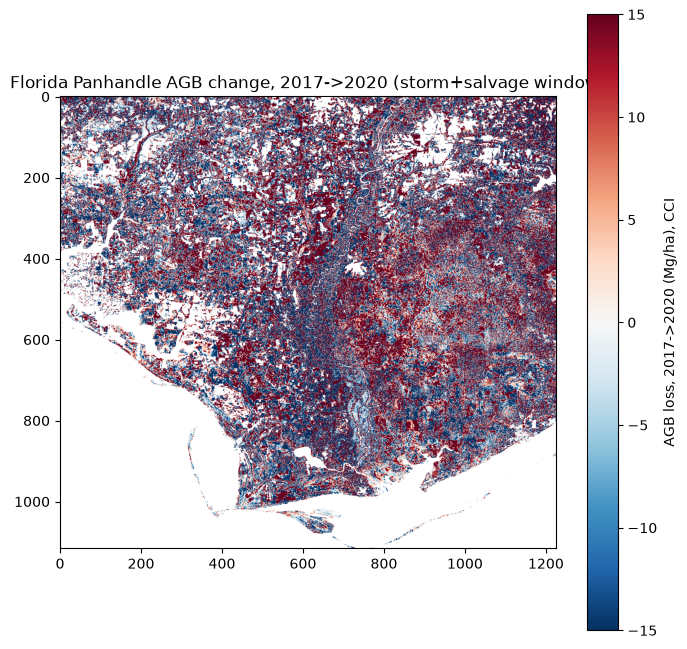

In [12]:
with rasterio.open("../data/raw/agb/agb_florida_v2_2017.tif") as src:
    agb_2017_v2 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_florida_v2_2020.tif") as src:
    agb_2020_v2 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss_florida_17_20 = agb_2017_v2 - agb_2020_v2

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_florida_17_20, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(im, label="AGB loss, 2017->2020 (Mg/ha), CCI")
plt.title("Florida Panhandle AGB change, 2017->2020 (storm+salvage window)")
plt.savefig("../data/raw/cci_loss_florida_2017_2020.png", dpi=150)
plt.show()


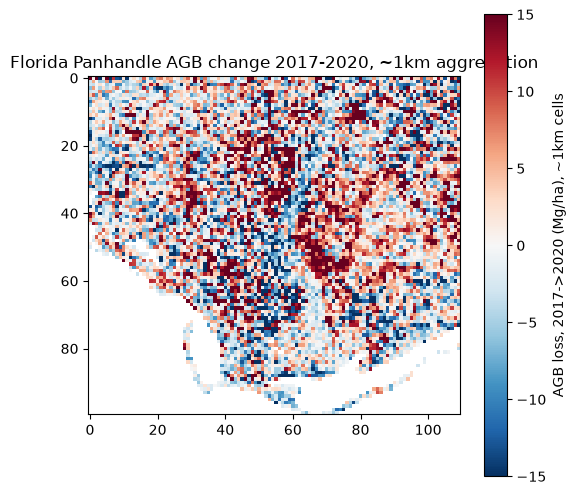

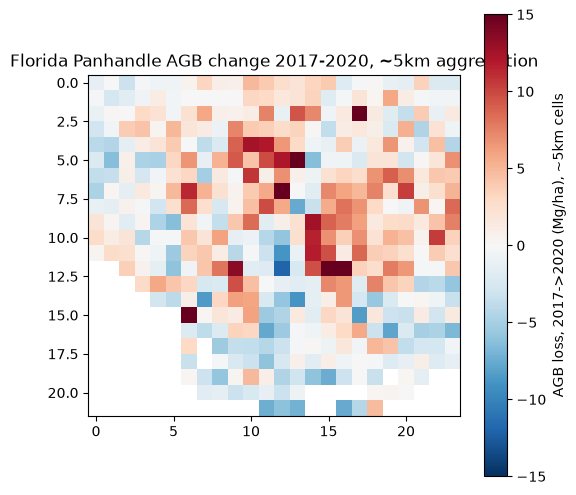

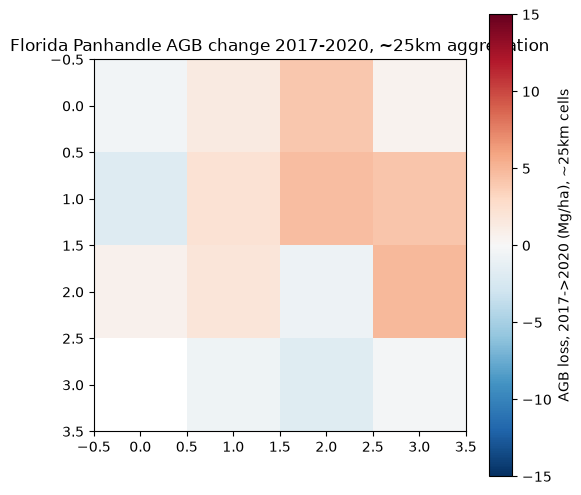

In [13]:
for label, cell_size in cell_sizes_deg.items():
    agb_2017_agg = aggregate("../data/raw/agb/agb_florida_v2_2017.tif", cell_size)
    agb_2020_agg = aggregate("../data/raw/agb/agb_florida_v2_2020.tif", cell_size)
    loss_agg = agb_2017_agg - agb_2020_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2017->2020 (Mg/ha), {label} cells")
    plt.title(f"Florida Panhandle AGB change 2017-2020, {label} aggregation")
    plt.savefig(f"../data/raw/cci_loss_florida_2017_2020_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()


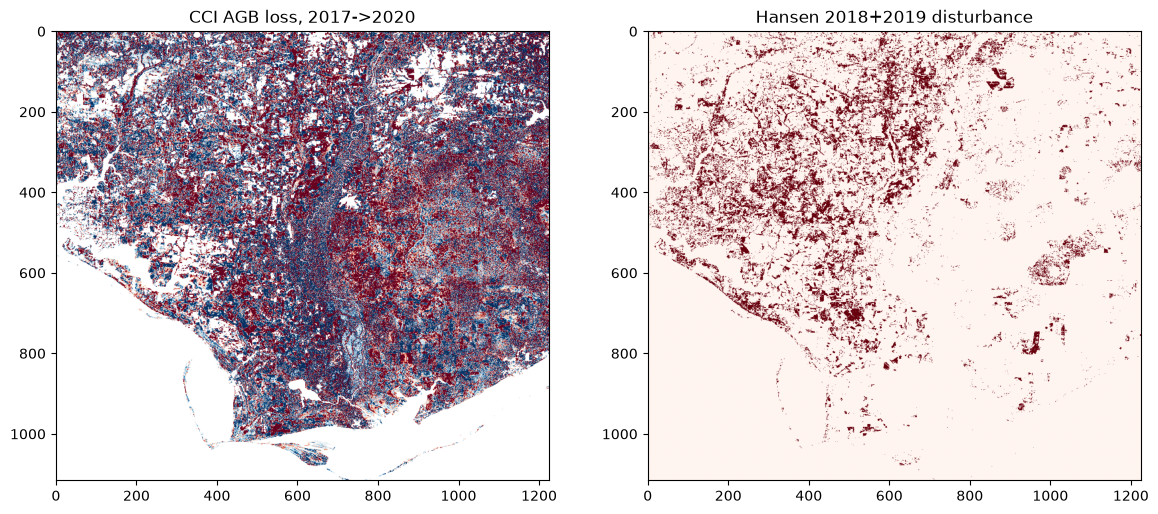

In [14]:
with rasterio.open("../data/raw/hansen_lossyear_florida_v2.tif") as src:
    lossyear_v2 = src.read(1)

disturbed_1819 = (lossyear_v2 == 18) | (lossyear_v2 == 19)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(loss_florida_17_20, cmap="RdBu_r", vmin=-15, vmax=15)
axes[0].set_title("CCI AGB loss, 2017->2020")
axes[1].imshow(disturbed_1819, cmap="Reds")
axes[1].set_title("Hansen 2018+2019 disturbance")
plt.savefig("../data/raw/cci_vs_hansen_florida.png", dpi=150)
plt.show()


In [15]:
import rasterio

with rasterio.open("../data/raw/baa_diff_absolute.tif") as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Shape:", src.shape)
    print("dtype:", src.dtypes)


CRS: ESRI:102039
Bounds: BoundingBox(left=955707.7891287737, bottom=781078.0500761499, right=1186107.7891287734, top=944918.0500761495)
Shape: (16384, 23040)
dtype: ('uint16',)


AOI in raster's CRS: (983592.8843341167, 779012.2750841742, 1101439.7851449044, 901346.4882267271)
Raster bounds: BoundingBox(left=955707.7891287737, bottom=781078.0500761499, right=1186107.7891287734, top=944918.0500761495)
Window: Window(col_off=np.float64(2788.5095205343023), row_off=np.float64(4357.15618494225), width=np.float64(11784.690081078787), height=np.float64(12233.421314255313))
Subset shape: (12027, 11785)


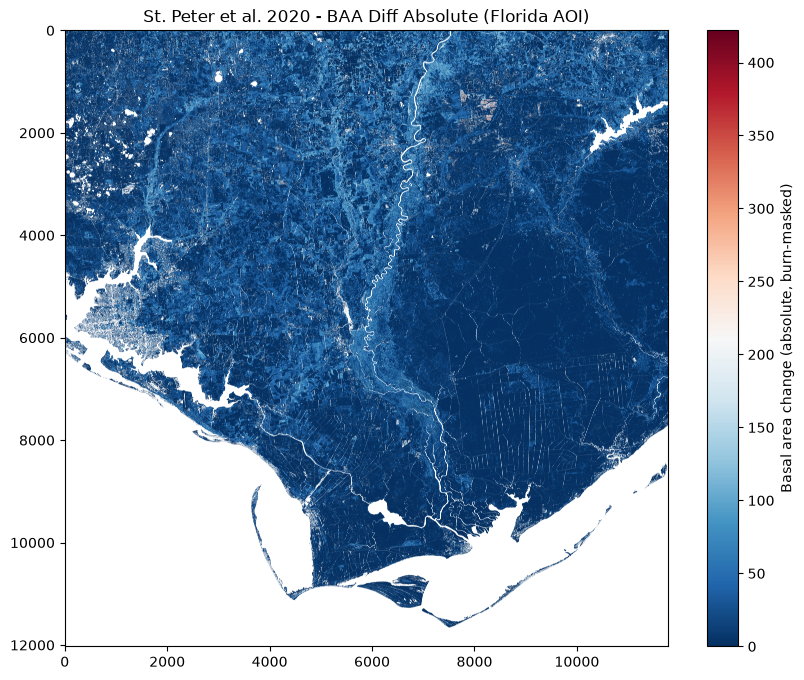

In [16]:
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt

florida_bounds_4326 = (-85.7, 29.6, -84.6, 30.6)  # lon_min, lat_min, lon_max, lat_max

with rasterio.open("../data/raw/baa_diff_absolute.tif") as src:
    aoi_bounds_proj = transform_bounds("EPSG:4326", src.crs, *florida_bounds_4326)
    print("AOI in raster's CRS:", aoi_bounds_proj)
    print("Raster bounds:", src.bounds)

    window = from_bounds(*aoi_bounds_proj, transform=src.transform)
    print("Window:", window)

    baa_diff_sub = src.read(1, window=window, masked=True).astype("float32").filled(np.nan)
    print("Subset shape:", baa_diff_sub.shape)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(baa_diff_sub, cmap="RdBu_r")
plt.colorbar(im, label="Basal area change (absolute, burn-masked)")
plt.title("St. Peter et al. 2020 - BAA Diff Absolute (Florida AOI)")
plt.savefig("../data/raw/st_peter_baa_diff_absolute_aoi.png", dpi=150)
plt.show()


In [17]:
print("min:", np.nanmin(baa_diff_sub), "max:", np.nanmax(baa_diff_sub))
print("5th/50th/95th percentile:", np.nanpercentile(baa_diff_sub, [5, 50, 95]))

with rasterio.open("../data/raw/baa_diff_absolute.tif") as src:
    print("nodata value:", src.nodata)


min: 0.0 max: 422.0
5th/50th/95th percentile: [ 0.  1. 77.]
nodata value: None


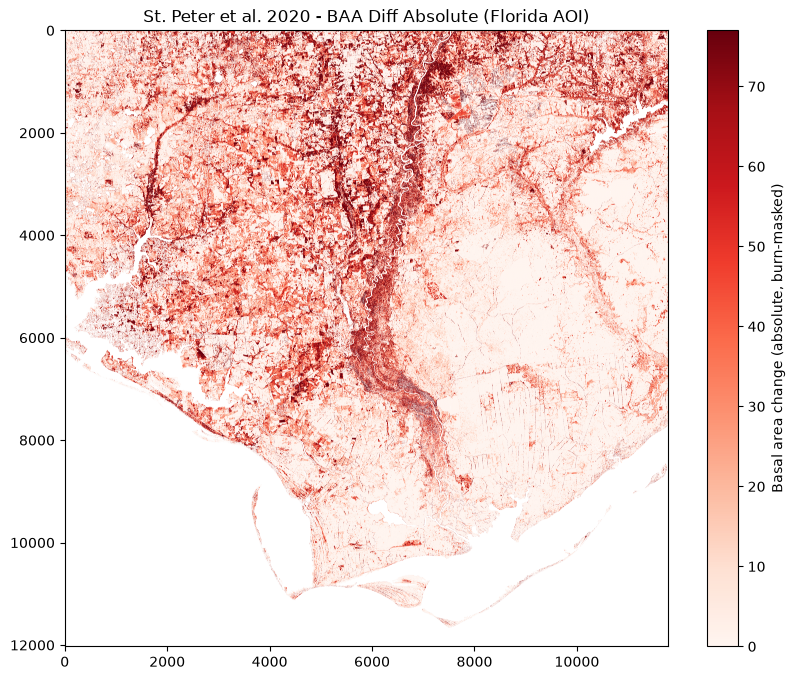

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(baa_diff_sub, cmap="Reds", vmin=0, vmax=77)
plt.colorbar(im, label="Basal area change (absolute, burn-masked)")
plt.title("St. Peter et al. 2020 - BAA Diff Absolute (Florida AOI)")
plt.savefig("../data/raw/st_peter_baa_diff_absolute_aoi_v2.png", dpi=150)
plt.show()


In [19]:
import rasterio

with rasterio.open("../data/raw/baa_diff_percent.tif") as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Shape:", src.shape)
    print("nodata:", src.nodata)


CRS: ESRI:102039
Bounds: BoundingBox(left=955707.7891287738, bottom=781078.0500761499, right=1186107.7891287738, top=944918.0500761495)
Shape: (16384, 23040)
nodata: None


In [20]:
import sys
sys.path.insert(0, "../src")
from grids import read_window, reproject_to_grid
from rasterio.warp import Resampling

baa_pct_arr, baa_pct_transform, baa_pct_crs = read_window(
    "../data/raw/baa_diff_percent.tif", florida_bounds_4326
)
print("St. Peter percent-loss subset shape:", baa_pct_arr.shape, baa_pct_crs)

with rasterio.open("../data/raw/agb/agb_florida_v2_2017.tif") as src:
    dst_transform = src.transform
    dst_crs = src.crs
    dst_shape = src.read(1).shape

baa_pct_on_cci_grid = reproject_to_grid(
    baa_pct_arr, baa_pct_transform, baa_pct_crs,
    dst_shape, dst_transform, dst_crs,
    resampling=Resampling.average,
)
print("reprojected shape:", baa_pct_on_cci_grid.shape, "matches CCI grid:", baa_pct_on_cci_grid.shape == loss_florida_17_20.shape)


St. Peter percent-loss subset shape: (12027, 11785) ESRI:102039
reprojected shape: (1116, 1225) matches CCI grid: True


In [21]:
valid = ~np.isnan(baa_pct_on_cci_grid) & ~np.isnan(loss_florida_17_20)
print("corr(St.Peter %% loss, CCI AGB loss):", np.corrcoef(baa_pct_on_cci_grid[valid], loss_florida_17_20[valid])[0, 1])
print("mean St.Peter %% loss inside Hansen-disturbed pixels:", np.nanmean(baa_pct_on_cci_grid[disturbed_1819]))
print("mean St.Peter %% loss outside Hansen-disturbed pixels:", np.nanmean(baa_pct_on_cci_grid[~disturbed_1819]))


corr(St.Peter %% loss, CCI AGB loss): 0.14495209516889984
mean St.Peter %% loss inside Hansen-disturbed pixels: 37.199963
mean St.Peter %% loss outside Hansen-disturbed pixels: 13.487002


In [ ]:
import zarr
import gcsfs
import pandas as pd

fs = gcsfs.GCSFileSystem(token="anon")
base = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
gust_arr = zarr.open(fs.get_mapper(f"{base}/instantaneous_10m_wind_gust"), mode="r")
lat_vals = zarr.open(fs.get_mapper(f"{base}/latitude"), mode="r")[:]
lon_vals = zarr.open(fs.get_mapper(f"{base}/longitude"), mode="r")[:]

lat_min, lat_max = 29.6, 30.6
lon_min_360, lon_max_360 = 360 - 85.7, 360 - 84.6  # 274.3, 275.4

lat_idx = np.where((lat_vals <= lat_max) & (lat_vals >= lat_min))[0]
lon_idx = np.where((lon_vals >= lon_min_360) & (lon_vals <= lon_max_360))[0]

t0 = pd.Timestamp("1900-01-01")
start_hr = int((pd.Timestamp("2018-10-09 00:00:00") - t0).total_seconds() // 3600)
end_hr = int((pd.Timestamp("2018-10-11 00:00:00") - t0).total_seconds() // 3600)

gust_sub = gust_arr[start_hr:end_hr + 1, lat_idx.min():lat_idx.max() + 1, lon_idx.min():lon_idx.max() + 1]
peak_gust_grid = np.nanmax(gust_sub, axis=0)

cell_lats = lat_vals[lat_idx.min():lat_idx.max() + 1]
cell_lons = lon_vals[lon_idx.min():lon_idx.max() + 1] - 360  # back to -180/180

print("peak_gust_grid shape:", peak_gust_grid.shape)
print("cell_lats:", cell_lats)
print("cell_lons:", cell_lons)
print(peak_gust_grid)


In [ ]:
from rasterio.transform import from_origin

cell_size_deg = 0.25
dst_west = cell_lons.min() - cell_size_deg / 2
dst_north = cell_lats.max() + cell_size_deg / 2
dst_shape = peak_gust_grid.shape  # (4, 4)
dst_transform = from_origin(dst_west, dst_north, cell_size_deg, cell_size_deg)
dst_crs = "EPSG:4326"

baa_pct_on_era5_grid = reproject_to_grid(
    baa_pct_arr, baa_pct_transform, baa_pct_crs,
    dst_shape, dst_transform, dst_crs,
    resampling=Resampling.average,
)
print(baa_pct_on_era5_grid.shape)
print(baa_pct_on_era5_grid)


In [ ]:
import numpy as np
from rasterio.transform import array_bounds

print("baa_pct_arr shape/stats:", baa_pct_arr.shape, np.nanmin(baa_pct_arr), np.nanmax(baa_pct_arr))
print("baa_pct_transform:", baa_pct_transform)
print("baa_pct_crs:", baa_pct_crs)
print("source bounds (own CRS):", array_bounds(baa_pct_arr.shape[0], baa_pct_arr.shape[1], baa_pct_transform))

print("dst_transform:", dst_transform)
print("dst_shape:", dst_shape)
print("dst bounds (EPSG:4326):", array_bounds(dst_shape[0], dst_shape[1], dst_transform))

from rasterio.warp import transform_bounds
src_bounds = array_bounds(baa_pct_arr.shape[0], baa_pct_arr.shape[1], baa_pct_transform)
src_bounds_4326 = transform_bounds(baa_pct_crs, "EPSG:4326", *src_bounds)
print("source bounds reprojected to EPSG:4326:", src_bounds_4326)


In [ ]:
import numpy as np
from rasterio.warp import transform_bounds

cell_size_deg = 0.25
loss_by_era5_cell = np.full(peak_gust_grid.shape, np.nan)
inv_transform = ~baa_pct_transform

for i, lat in enumerate(cell_lats):
    for j, lon in enumerate(cell_lons):
        w, s, e, n = lon - cell_size_deg/2, lat - cell_size_deg/2, lon + cell_size_deg/2, lat + cell_size_deg/2
        w, s, e, n = transform_bounds("EPSG:4326", baa_pct_crs, w, s, e, n)

        col_min, row_max = inv_transform * (w, s)
        col_max, row_min = inv_transform * (e, n)
        row_min, row_max = int(max(row_min, 0)), int(min(row_max, baa_pct_arr.shape[0]))
        col_min, col_max = int(max(col_min, 0)), int(min(col_max, baa_pct_arr.shape[1]))

        sub = baa_pct_arr[row_min:row_max, col_min:col_max]
        loss_by_era5_cell[i, j] = np.nanmean(sub) if sub.size > 0 else np.nan

print(loss_by_era5_cell)


In [22]:
import pandas as pd

ibtracs = pd.read_csv("../data/raw/ibtracs_na.csv", skiprows=[1], low_memory=False)
michael = ibtracs[(ibtracs["NAME"] == "MICHAEL") & (ibtracs["SEASON"] == 2018)].copy()
michael["ISO_TIME"] = pd.to_datetime(michael["ISO_TIME"])
michael["LAT"] = michael["LAT"].astype(float)
michael["LON"] = michael["LON"].astype(float)
michael["USA_WIND"] = pd.to_numeric(michael["USA_WIND"], errors="coerce")

print(michael[["ISO_TIME", "LAT", "LON", "USA_WIND"]].to_string())


                  ISO_TIME   LAT   LON  USA_WIND
119635 2018-10-06 18:00:00  17.8 -86.6        25
119636 2018-10-06 21:00:00  18.0 -86.8        25
119637 2018-10-07 00:00:00  18.1 -86.9        25
119638 2018-10-07 03:00:00  18.2 -86.9        28
119639 2018-10-07 06:00:00  18.4 -86.8        30
119640 2018-10-07 09:00:00  18.6 -86.6        33
119641 2018-10-07 12:00:00  18.8 -86.4        35
119642 2018-10-07 15:00:00  18.9 -86.0        40
119643 2018-10-07 18:00:00  19.1 -85.7        45
119644 2018-10-07 21:00:00  19.4 -85.6        48
119645 2018-10-08 00:00:00  19.7 -85.5        50
119646 2018-10-08 03:00:00  19.9 -85.5        55
119647 2018-10-08 06:00:00  20.2 -85.4        60
119648 2018-10-08 09:00:00  20.5 -85.2        63
119649 2018-10-08 12:00:00  20.9 -85.1        65
119650 2018-10-08 15:00:00  21.3 -85.1        70
119651 2018-10-08 18:00:00  21.7 -85.1        75
119652 2018-10-08 21:00:00  22.2 -85.1        80
119653 2018-10-09 00:00:00  22.7 -85.2        85
119654 2018-10-09 03

In [23]:
import numpy as np
from rasterio.transform import xy

track_lats = michael["LAT"].values
track_lons = michael["LON"].values

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

rows, cols = np.indices(baa_pct_on_cci_grid.shape)
pixel_lons, pixel_lats = xy(dst_transform, rows.ravel(), cols.ravel())
pixel_lons = np.array(pixel_lons)
pixel_lats = np.array(pixel_lats)

# distance from every pixel to every track point, take the minimum
dist_matrix = haversine(
    pixel_lats[:, None], pixel_lons[:, None],
    track_lats[None, :], track_lons[None, :],
)
dist_to_track = dist_matrix.min(axis=1).reshape(baa_pct_on_cci_grid.shape)

print("distance range (km):", np.nanmin(dist_to_track), np.nanmax(dist_to_track))


distance range (km): 0.04374187392616517 97.56826080255507


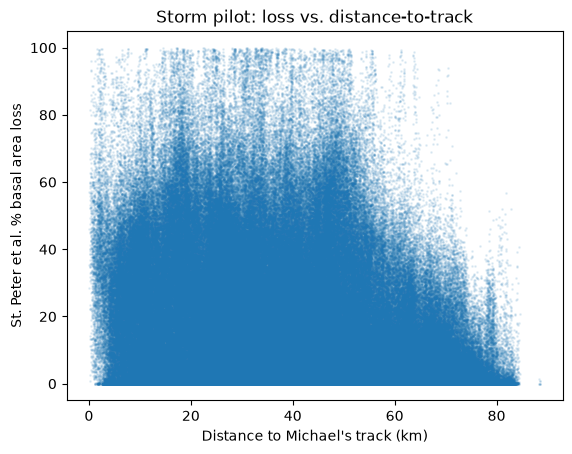

1     24.743975
2     23.619461
3     27.672449
4     25.303196
5     19.508835
6     17.440956
7     12.226854
8      7.768668
9      5.534764
10     2.721035
dtype: float32


In [24]:
import matplotlib.pyplot as plt

valid = ~np.isnan(baa_pct_on_cci_grid)
plt.scatter(dist_to_track[valid], baa_pct_on_cci_grid[valid], s=1, alpha=0.1)
plt.xlabel("Distance to Michael's track (km)")
plt.ylabel("St. Peter et al. % basal area loss")
plt.title("Storm pilot: loss vs. distance-to-track")
plt.savefig("../data/raw/storm_loss_vs_distance.png", dpi=150)
plt.show()

# binned version for a cleaner signal
bins = np.linspace(0, np.nanpercentile(dist_to_track[valid], 95), 10)
bin_idx = np.digitize(dist_to_track[valid], bins)
binned_loss = pd.Series(baa_pct_on_cci_grid[valid]).groupby(bin_idx).mean()
print(binned_loss)


In [25]:
with rasterio.open("../data/raw/agb/agb_florida_v2_2017.tif") as src:
    cci_transform = src.transform
    cci_crs = src.crs

rows, cols = np.indices(baa_pct_on_cci_grid.shape)
pixel_lons, pixel_lats = xy(cci_transform, rows.ravel(), cols.ravel())
pixel_lons = np.array(pixel_lons)
pixel_lats = np.array(pixel_lats)

dist_matrix = haversine(
    pixel_lats[:, None], pixel_lons[:, None],
    track_lats[None, :], track_lons[None, :],
)
dist_to_track = np.nanmin(dist_matrix, axis=1).reshape(baa_pct_on_cci_grid.shape)

print("distance range (km):", np.nanmin(dist_to_track), np.nanmax(dist_to_track))


distance range (km): 0.04374187392616517 97.56826080255507


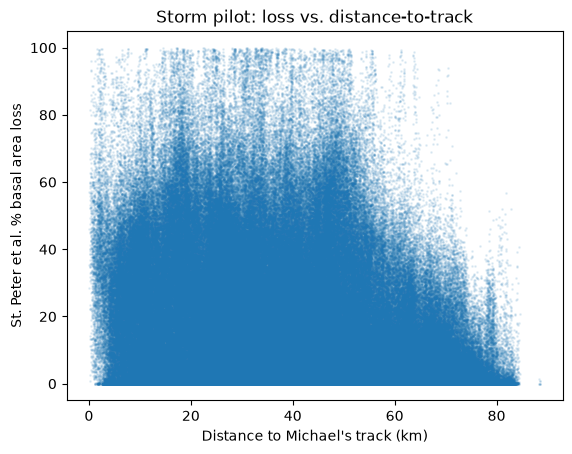

1     24.743975
2     23.619461
3     27.672449
4     25.303196
5     19.508835
6     17.440956
7     12.226854
8      7.768668
9      5.534764
10     2.721035
dtype: float32


In [26]:
valid = ~np.isnan(baa_pct_on_cci_grid)
plt.scatter(dist_to_track[valid], baa_pct_on_cci_grid[valid], s=1, alpha=0.1)
plt.xlabel("Distance to Michael's track (km)")
plt.ylabel("St. Peter et al. % basal area loss")
plt.title("Storm pilot: loss vs. distance-to-track")
plt.savefig("../data/raw/storm_loss_vs_distance.png", dpi=150)
plt.show()

bins = np.linspace(0, np.nanpercentile(dist_to_track[valid], 95), 10)
bin_idx = np.digitize(dist_to_track[valid], bins)
binned_loss = pd.Series(baa_pct_on_cci_grid[valid]).groupby(bin_idx).mean()
print(binned_loss)


In [27]:
import pandas as pd

n_bins = 12
valid = ~np.isnan(baa_pct_on_cci_grid)
bin_edges = np.linspace(0, np.nanmax(dist_to_track[valid]), n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_idx = np.clip(np.digitize(dist_to_track[valid], bin_edges) - 1, 0, n_bins - 1)

binned_df = pd.DataFrame({
    "dist": dist_to_track[valid],
    "loss": baa_pct_on_cci_grid[valid],
    "bin": bin_idx,
})
curve_points = binned_df.groupby("bin").agg(
    dist_center=("dist", "mean"), loss_mean=("loss", "mean"), n=("loss", "size")
)
print(curve_points)


     dist_center  loss_mean      n
bin                               
0       4.909836  25.042597  20677
1      11.200774  22.833965  50082
2      18.515193  28.554569  51886
3      26.008404  26.397230  61713
4      33.254864  21.229679  76166
5      40.566974  18.110786  83543
6      47.982860  16.563957  94344
7      55.213826  10.330682  80408
8      62.600693   7.449179  63344
9      69.942927   5.366486  55251
10     76.290220   2.639420  29605
11     82.323275   3.261449   2009


L_max=26.04  L_min=2.24  d0=49.86  k=9.43
R^2 (on binned means): 0.9681256938857226


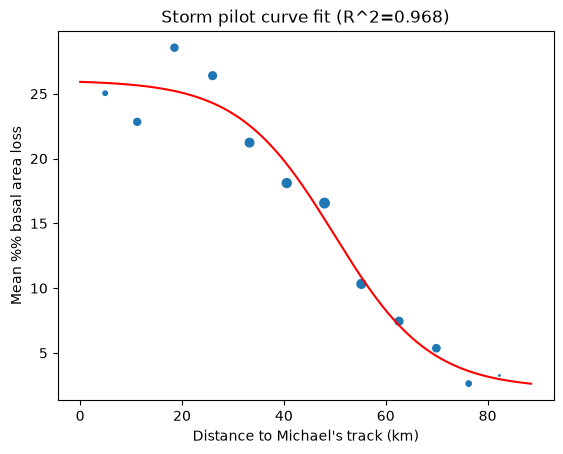

In [28]:
from scipy.optimize import curve_fit

def logistic_decay(d, L_max, L_min, d0, k):
    return L_min + (L_max - L_min) / (1 + np.exp((d - d0) / k))

p0 = [25, 3, 50, 10]
popt, pcov = curve_fit(
    logistic_decay, curve_points["dist_center"], curve_points["loss_mean"],
    p0=p0, maxfev=10000,
)
L_max, L_min, d0, k = popt
print(f"L_max={L_max:.2f}  L_min={L_min:.2f}  d0={d0:.2f}  k={k:.2f}")

pred = logistic_decay(curve_points["dist_center"], *popt)
ss_res = np.sum((curve_points["loss_mean"] - pred) ** 2)
ss_tot = np.sum((curve_points["loss_mean"] - curve_points["loss_mean"].mean()) ** 2)
r2 = 1 - ss_res / ss_tot
print("R^2 (on binned means):", r2)

d_plot = np.linspace(0, bin_edges[-1], 200)
plt.scatter(curve_points["dist_center"], curve_points["loss_mean"], s=curve_points["n"] / 2000)
plt.plot(d_plot, logistic_decay(d_plot, *popt), color="red")
plt.xlabel("Distance to Michael's track (km)")
plt.ylabel("Mean %% basal area loss")
plt.title(f"Storm pilot curve fit (R^2={r2:.3f})")
plt.savefig("../data/raw/storm_curve_fit.png", dpi=150)
plt.show()


In [29]:
print(michael[["ISO_TIME", "LAT", "LON", "USA_WIND", "USA_RMW"]].to_string())


                  ISO_TIME   LAT   LON  USA_WIND USA_RMW
119635 2018-10-06 18:00:00  17.8 -86.6        25      90
119636 2018-10-06 21:00:00  18.0 -86.8        25      90
119637 2018-10-07 00:00:00  18.1 -86.9        25      90
119638 2018-10-07 03:00:00  18.2 -86.9        28     105
119639 2018-10-07 06:00:00  18.4 -86.8        30     120
119640 2018-10-07 09:00:00  18.6 -86.6        33     120
119641 2018-10-07 12:00:00  18.8 -86.4        35     120
119642 2018-10-07 15:00:00  18.9 -86.0        40      90
119643 2018-10-07 18:00:00  19.1 -85.7        45      60
119644 2018-10-07 21:00:00  19.4 -85.6        48      48
119645 2018-10-08 00:00:00  19.7 -85.5        50      35
119646 2018-10-08 03:00:00  19.9 -85.5        55      35
119647 2018-10-08 06:00:00  20.2 -85.4        60      35
119648 2018-10-08 09:00:00  20.5 -85.2        63      33
119649 2018-10-08 12:00:00  20.9 -85.1        65      30
119650 2018-10-08 15:00:00  21.3 -85.1        70      28
119651 2018-10-08 18:00:00  21.

In [30]:
track_wind_ms = michael["USA_WIND"].values * 0.514444  # knots -> m/s
track_rmw_km = pd.to_numeric(michael["USA_RMW"], errors="coerce").values * 1.852  # nm -> km

# find each pixel's NEAREST track point (not just the distance) so we use that point's own wind/RMW
dist_matrix_clean = np.where(np.isnan(dist_matrix), np.inf, dist_matrix)
nearest_idx = np.argmin(dist_matrix_clean, axis=1)
dist_to_track_flat = dist_matrix_clean[np.arange(len(nearest_idx)), nearest_idx]

dist_to_track = dist_to_track_flat.reshape(baa_pct_on_cci_grid.shape)
nearest_idx_grid = nearest_idx.reshape(baa_pct_on_cci_grid.shape)

Vmax_grid = track_wind_ms[nearest_idx_grid]
Rmax_grid = track_rmw_km[nearest_idx_grid]

# modified Rankine vortex: full Vmax inside RMW, power-law decay outside
decay_exp = 0.5
wind_estimate = np.where(
    dist_to_track <= Rmax_grid,
    Vmax_grid,
    Vmax_grid * (Rmax_grid / np.maximum(dist_to_track, 1e-6)) ** decay_exp,
)

print("wind_estimate range (m/s):", np.nanmin(wind_estimate[valid]), np.nanmax(wind_estimate[valid]))
print("mean RMW used (km):", np.nanmean(Rmax_grid[valid]))


wind_estimate range (m/s): 33.08413075972041 72.02216
mean RMW used (km): 26.0457950040955


In [31]:
n_bins = 12
bin_edges_w = np.linspace(np.nanmin(wind_estimate[valid]), np.nanmax(wind_estimate[valid]), n_bins + 1)
bin_idx_w = np.clip(np.digitize(wind_estimate[valid], bin_edges_w) - 1, 0, n_bins - 1)

binned_df_w = pd.DataFrame({
    "wind": wind_estimate[valid],
    "loss": baa_pct_on_cci_grid[valid],
    "bin": bin_idx_w,
})
curve_points_w = binned_df_w.groupby("bin").agg(
    wind_center=("wind", "mean"), loss_mean=("loss", "mean"), n=("loss", "size")
)
print(curve_points_w)


     wind_center  loss_mean       n
bin                                
0      35.301693  11.859025   10158
1      37.977558  13.432178   29140
2      41.547086  11.803260   71221
3      44.344472   6.681013   78664
4      47.657681   5.680099   67651
5      50.922186   8.649518   60424
6      54.119923  16.109251   53867
7      57.364212  20.881762   45717
8      60.591717  21.731621   36090
9      63.893272  25.713112   30527
10     67.111474  26.356997   26012
11     69.810743  26.863350  159557


L_max=25.82  L_min=9.65  w0=55.93 m/s  k=2.03
R^2 (wind-based): 0.8981986803083336


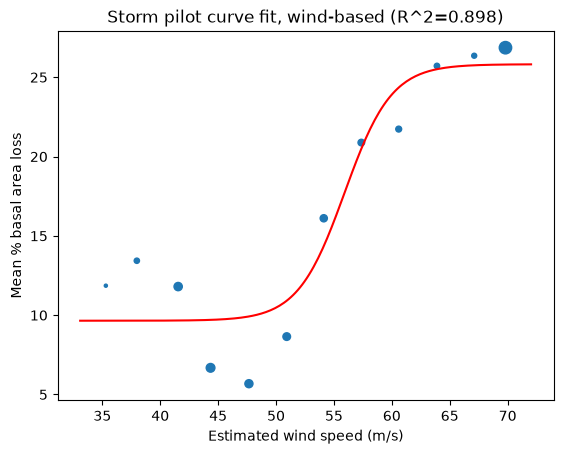

In [32]:
def logistic_increasing(w, L_max, L_min, w0, k):
    return L_min + (L_max - L_min) / (1 + np.exp(-(w - w0) / k))

p0 = [26, 3, 55, 5]
popt_w, pcov_w = curve_fit(
    logistic_increasing, curve_points_w["wind_center"], curve_points_w["loss_mean"],
    p0=p0, maxfev=10000,
)
L_max, L_min, w0, k = popt_w
print(f"L_max={L_max:.2f}  L_min={L_min:.2f}  w0={w0:.2f} m/s  k={k:.2f}")

pred_w = logistic_increasing(curve_points_w["wind_center"], *popt_w)
ss_res = np.sum((curve_points_w["loss_mean"] - pred_w) ** 2)
ss_tot = np.sum((curve_points_w["loss_mean"] - curve_points_w["loss_mean"].mean()) ** 2)
r2_w = 1 - ss_res / ss_tot
print("R^2 (wind-based):", r2_w)

w_plot = np.linspace(bin_edges_w[0], bin_edges_w[-1], 200)
plt.scatter(curve_points_w["wind_center"], curve_points_w["loss_mean"], s=curve_points_w["n"] / 2000)
plt.plot(w_plot, logistic_increasing(w_plot, *popt_w), color="red")
plt.xlabel("Estimated wind speed (m/s)")
plt.ylabel("Mean % basal area loss")
plt.title(f"Storm pilot curve fit, wind-based (R^2={r2_w:.3f})")
plt.savefig("../data/raw/storm_curve_fit_wind.png", dpi=150)
plt.show()


In [33]:
import os
os.makedirs("../data/processed", exist_ok=True)

storm_fits = pd.DataFrame([{
    "curve_type": "wind_speed_logistic",
    "L_max": L_max, "L_min": L_min, "w0": w0, "k": k,
    "r_squared": r2_w,
}])
storm_fits.to_csv("../data/processed/storm_fits.csv", index=False)


1-sigma parameter uncertainty: {'L_max': np.float64(1.7895591211465234), 'L_min': np.float64(1.3411856013760364), 'w0': np.float64(1.3820456879474057), 'k': np.float64(1.1924987940078493)}


/var/tmp/ipykernel_733332/1478910374.py:11: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_b, _ = curve_fit(logistic_increasing, curve_points_w["wind_center"].values[idx],
/var/tmp/ipykernel_733332/818429784.py:2: RuntimeWarning: overflow encountered in exp
  return L_min + (L_max - L_min) / (1 + np.exp(-(w - w0) / k))


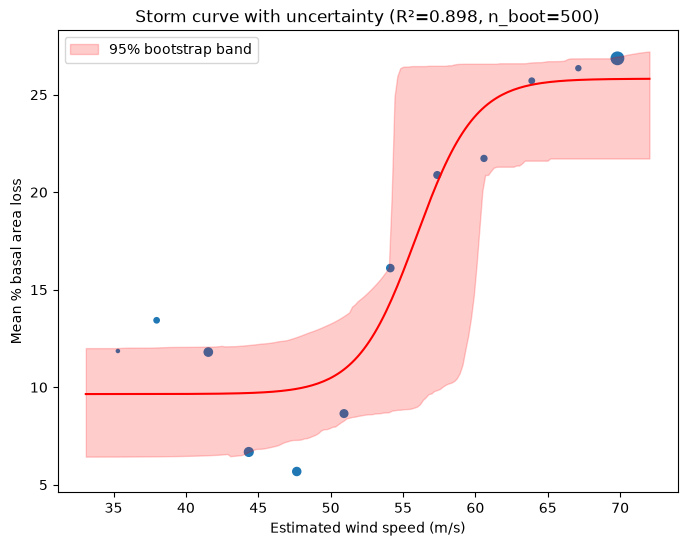

In [36]:
param_std = np.sqrt(np.diag(pcov_w))
print("1-sigma parameter uncertainty:", dict(zip(["L_max","L_min","w0","k"], param_std)))

n_boot = 500
boot_curves = []
w_plot = np.linspace(bin_edges_w[0], bin_edges_w[-1], 200)
rng = np.random.default_rng(0)
for _ in range(n_boot):
    idx = rng.choice(len(curve_points_w), len(curve_points_w), replace=True)
    try:
        popt_b, _ = curve_fit(logistic_increasing, curve_points_w["wind_center"].values[idx],
                               curve_points_w["loss_mean"].values[idx], p0=popt_w, maxfev=10000)
        boot_curves.append(logistic_increasing(w_plot, *popt_b))
    except RuntimeError:
        continue
boot_curves = np.array(boot_curves)
lo, hi = np.percentile(boot_curves, [2.5, 97.5], axis=0)

plt.figure(figsize=(8,6))
plt.scatter(curve_points_w["wind_center"], curve_points_w["loss_mean"], s=curve_points_w["n"]/2000)
plt.plot(w_plot, logistic_increasing(w_plot, *popt_w), color="red")
plt.fill_between(w_plot, lo, hi, color="red", alpha=0.2, label="95% bootstrap band")
plt.xlabel("Estimated wind speed (m/s)"); plt.ylabel("Mean % basal area loss")
plt.title(f"Storm curve with uncertainty (R²={r2_w:.3f}, n_boot={len(boot_curves)})")
plt.legend()
plt.savefig("../data/processed/storm_curve_with_uncertainty.png", dpi=150)
plt.show()


In [35]:
boot_curves = []
for _ in range(n_boot):
    idx = rng.choice(len(curve_points_w), len(curve_points_w), replace=True)
    try:
        popt_b, _ = curve_fit(logistic_increasing, curve_points_w["wind_center"].values[idx],
                               curve_points_w["loss_mean"].values[idx], p0=popt_w, maxfev=10000,
                               bounds=([0, 0, 20, 0.5], [50, 20, 90, 30]))  # keep params physically sensible
        boot_curves.append(logistic_increasing(w_plot, *popt_b))
    except RuntimeError:
        continue


In [37]:
plt.savefig("../data/processed/storm_curve_with_uncertainty.png", dpi=150)


<Figure size 640x480 with 0 Axes>

In [41]:
valid_flat = valid.ravel()

median_lon = np.median(pixel_lons[valid_flat])
east_mask = pixel_lons[valid_flat] >= median_lon
west_mask = ~east_mask

def bin_wind_loss(wind_arr, loss_arr, n_bins=8):
    edges = np.linspace(np.nanmin(wind_arr), np.nanmax(wind_arr), n_bins + 1)
    idx = np.clip(np.digitize(wind_arr, edges) - 1, 0, n_bins - 1)
    df = pd.DataFrame({"wind": wind_arr, "loss": loss_arr, "bin": idx})
    return df.groupby("bin").agg(wind_center=("wind", "mean"), loss_mean=("loss", "mean"),
                                   n=("loss", "size")).dropna()

wind_valid = wind_estimate[valid]
loss_valid = baa_pct_on_cci_grid[valid]

east_bins = bin_wind_loss(wind_valid[east_mask], loss_valid[east_mask])
west_bins = bin_wind_loss(wind_valid[west_mask], loss_valid[west_mask])

bounds = ([0, 0, 20, 0.5], [50, 20, 90, 30])

popt_east, _ = curve_fit(logistic_increasing, east_bins["wind_center"], east_bins["loss_mean"],
                          p0=popt_w, maxfev=10000, bounds=bounds)
pred_on_west = logistic_increasing(west_bins["wind_center"], *popt_east)
corr_e2w = np.corrcoef(west_bins["loss_mean"], pred_on_west)[0, 1]
rmse_e2w = np.sqrt(np.mean((west_bins["loss_mean"] - pred_on_west) ** 2))

popt_west, _ = curve_fit(logistic_increasing, west_bins["wind_center"], west_bins["loss_mean"],
                          p0=popt_w, maxfev=10000, bounds=bounds)
pred_on_east = logistic_increasing(east_bins["wind_center"], *popt_west)
corr_w2e = np.corrcoef(east_bins["loss_mean"], pred_on_east)[0, 1]
rmse_w2e = np.sqrt(np.mean((east_bins["loss_mean"] - pred_on_east) ** 2))

print("East-fit -> predict West:  corr =", corr_e2w, " RMSE =", rmse_e2w)
print("West-fit -> predict East:  corr =", corr_w2e, " RMSE =", rmse_w2e)
print("\nEast params:", dict(zip(["L_max","L_min","w0","k"], popt_east)))
print("West params:", dict(zip(["L_max","L_min","w0","k"], popt_west)))


East-fit -> predict West:  corr = 0.8008352024715627  RMSE = 9.697116912108418
West-fit -> predict East:  corr = 0.5362085932166053  RMSE = 7.340743465821017

East params: {'L_max': np.float64(14.727781599777035), 'L_min': np.float64(9.66169447334623), 'w0': np.float64(56.19686359435615), 'k': np.float64(0.500000000000036)}
West params: {'L_max': np.float64(26.015100041520796), 'L_min': np.float64(9.289663810264388), 'w0': np.float64(53.10203790456696), 'k': np.float64(0.5000000000001773)}


In [42]:
# null baseline: just predict the training half's mean loss, no curve at all
null_rmse_e2w = np.sqrt(np.mean((west_bins["loss_mean"] - east_bins["loss_mean"].mean()) ** 2))
null_rmse_w2e = np.sqrt(np.mean((east_bins["loss_mean"] - west_bins["loss_mean"].mean()) ** 2))

skill_e2w = 1 - (rmse_e2w / null_rmse_e2w) ** 2   # out-of-sample R², a.k.a. Nash-Sutcliffe efficiency
skill_w2e = 1 - (rmse_w2e / null_rmse_w2e) ** 2

print(f"East->West: curve RMSE={rmse_e2w:.2f} vs null RMSE={null_rmse_e2w:.2f}  ->  skill = {skill_e2w:.3f}")
print(f"West->East: curve RMSE={rmse_w2e:.2f} vs null RMSE={null_rmse_w2e:.2f}  ->  skill = {skill_w2e:.3f}")


East->West: curve RMSE=9.70 vs null RMSE=11.94  ->  skill = 0.340
West->East: curve RMSE=7.34 vs null RMSE=8.98  ->  skill = 0.332


In [43]:
storm_fits["skill_e2w"] = skill_e2w
storm_fits["skill_w2e"] = skill_w2e
storm_fits["holdout_note"] = "spatial (east/west) holdout within Michael only, not cross-storm"
storm_fits.to_csv("../data/processed/storm_fits.csv", index=False)
